# Food Orders — ETL, Analysis & Visualization
This notebook covers the **seven task sections** provided in the assignment. Every code cell has a Markdown explanation immediately before it, and every task ends with a conclusion. Keep `food_orders.csv` beside this notebook or update `CSV_PATH`. Run cells from top to bottom. `raw_df` is the original data; `work_df` is the cleaned copy.

## Task 1 — Load and understand the dataset
Import Pandas for data handling, NumPy for missing numeric values, and Matplotlib for charts. Then load the CSV into `raw_df` as requested.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
raw_df = pd.read_csv("food_orders.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


### Preview records
`head()` and `tail()` show the first and last five rows. `sample()` gives five randomly selected rows to help inspect the data variety.

In [3]:
display(raw_df.head())
display(raw_df.tail())
display(raw_df.sample(n=min(5, len(raw_df)), random_state=42))

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,NaN,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
629,630,C1716,R2905,2024-01-13 04:16:47,2024-01-13 06:09:47,NaN,0.0,Cash on Delivery,5% on App,91.0,42.0,100.0,Rainy,Mobile App
788,789,C9659,R2778,2024-01-31 10:35:46,2024-01-31 12:07:46,714.0,40.0,Cash on Delivery,NaN,178.0,25.0,150.0,Rainy,Partner App
684,685,C7254,R2538,2024-01-07 23:31:43,2024-01-08 01:04:43,204.0,40.0,Digital Wallet,NaN,195.0,11.0,0.0,Cloudy,Mobile App
516,517,C8494,R2687,2024-01-23 05:41:17,2024-01-23 06:24:17,948.0,50.0,NaN,NaN,106.0,28.0,0.0,Sunny,Mobile App
529,530,C5268,R2697,2024-02-04 18:17:27,2024-02-04 18:51:27,1815.0,50.0,Cash on Delivery,15% New User,114.0,33.0,0.0,Sunny,Mobile App


### Dataset dimensions, columns, and types
`shape` gives row/column counts, `columns` lists field names, and `dtypes`/`info()` show how Pandas currently interprets each column.

In [4]:
print("Rows and columns:", raw_df.shape)
print("\nColumn names:", raw_df.columns.tolist())
display(raw_df.dtypes.to_frame("Data Type"))
raw_df.info()

Rows and columns: (1010, 14)

Column names: ['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']


,Data Type
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,str
Delivery Date and Time,str
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64


<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1010 non-null   int64  
 1   Customer ID             1010 non-null   str    
 2   Restaurant ID           1010 non-null   str    
 3   Order Date and Time     1010 non-null   str    
 4   Delivery Date and Time  1010 non-null   str    
 5   Order Value             969 non-null    float64
 6   Delivery Fee            960 non-null    float64
 7   Payment Method          960 non-null    str    
 8   Discounts and Offers    768 non-null    str    
 9   Commission Fee          970 non-null    float64
 10  Payment Processing Fee  959 non-null    float64
 11  Refunds/Chargebacks     970 non-null    float64
 12  Weather Condition       1010 non-null   str    
 13  Order Channel           1010 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 110.6

### Numeric and categorical summaries
`describe()` summarizes numeric columns. `describe(include='object')` summarizes text/category columns, including unique values and the most frequent category.

In [5]:
display(raw_df.describe())
display(raw_df.describe(include="object"))

,Order ID,Order Value,Delivery Fee,Commission Fee,Payment Processing Fee,Refunds/Chargebacks
count,1010.000000,969.000000,960.000000,970.000000,959.000000,970.000000
mean,499.221782,1055.901961,28.625000,127.042268,29.895725,27.886598
std,288.589479,529.534182,16.927281,43.013345,11.731583,49.383898
min,1.000000,104.000000,0.000000,50.000000,10.000000,0.000000
25%,248.250000,600.000000,20.000000,90.250000,20.000000,0.000000
50%,498.500000,1041.000000,30.000000,128.000000,30.000000,0.000000
75%,748.750000,1494.000000,40.000000,164.000000,40.000000,50.000000
max,1000.000000,1995.000000,50.000000,200.000000,50.000000,150.000000


C:\Users\Abdul Vadud\AppData\Local\Temp\ipykernel_42040\1073195070.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw_df.describe(include="object"))


,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Payment Method,Discounts and Offers,Weather Condition,Order Channel
count,1010,1010,1010,1010,960,768,1010,1010
unique,947,621,1000,1000,3,4,4,3
top,C7949,R2317,2024-02-05 05:55:15,2024-02-05 07:33:15,Cash on Delivery,10%,Sunny,Mobile App
freq,3,6,2,2,341,221,405,693


### Column meaning and expected type
This data dictionary uses the field names specified in the assignment. Additional fields are marked for inspection. Expected type describes the analytical role, not necessarily the current Pandas dtype.

In [6]:
descriptions = {
    "Order ID": ("Order/transaction identifier", "Identifier"),
    "Customer ID": ("Customer identifier", "Identifier"),
    "Restaurant ID": ("Restaurant identifier", "Identifier"),
    "Order Date and Time": ("When the order was placed", "Datetime"),
    "Delivery Date and Time": ("When the order was delivered", "Datetime"),
    "Order Value": ("Monetary order value", "Numeric"),
    "Delivery Fee": ("Delivery charge", "Numeric"),
    "Payment Method": ("Method used to pay", "Category"),
    "Discounts and Offers": ("Discount or promotional offer details", "Category"),
    "Commission Fee": ("Platform commission amount", "Numeric"),
    "Payment Processing Fee": ("Payment processing cost", "Numeric"),
    "Refunds/Chargebacks": ("Refund or chargeback amount", "Numeric"),
    "Weather Condition": ("Weather category", "Category"),
    "Order Channel": ("Channel used to place the order", "Category"),
    "Delivery Duration (Minutes)": ("Existing delivery duration, if supplied", "Numeric")
}
data_dictionary = pd.DataFrame([
    {"Column": c,
     "What it appears to contain": descriptions.get(c, ("Inspect values to identify meaning", "Needs inspection"))[0],
     "Expected type": descriptions.get(c, ("", "Needs inspection"))[1],
     "Actual Pandas dtype": str(raw_df[c].dtype)}
    for c in raw_df.columns
])
display(data_dictionary)

,Column,What it appears to contain,Expected type,Actual Pandas dtype
0,Order ID,Order/transaction identifier,Identifier,int64
1,Customer ID,Customer identifier,Identifier,str
2,Restaurant ID,Restaurant identifier,Identifier,str
3,Order Date and Time,When the order was placed,Datetime,str
4,Delivery Date and Time,When the order was delivered,Datetime,str
5,Order Value,Monetary order value,Numeric,float64
6,Delivery Fee,Delivery charge,Numeric,float64
7,Payment Method,Method used to pay,Category,str
8,Discounts and Offers,Discount or promotional offer details,Category,str
9,Commission Fee,Platform commission amount,Numeric,float64


### Task 1 — Conclusion
One row is expected to represent **one food order/transaction**. `Order Value` supports order-value analysis; the order and delivery timestamps support delivery analysis; `Payment Method` and `Order Channel` support payment/channel analysis; and `Commission Fee`, `Delivery Fee`, `Payment Processing Fee`, and `Refunds/Chargebacks` are used in the simplified platform revenue formula. Confirm these meanings against actual values or dataset documentation.

## Task 2 — Perform a data-quality assessment
The following cells assess missingness, duplicates, identifier repetition, data types, timestamps, financial values, delivery duration, and category frequencies. The original `raw_df` is not cleaned or overwritten.

### Missing-value counts and percentages
`isna().sum()` counts missing cells. Dividing by the number of rows and multiplying by 100 calculates each column's missing percentage.

In [7]:
missing_summary = pd.DataFrame({
    "Missing Values": raw_df.isna().sum(),
    "Missing Percentage": (raw_df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary)

,Missing Values,Missing Percentage
Discounts and Offers,242,23.96
Payment Processing Fee,51,5.05
Delivery Fee,50,4.95
Payment Method,50,4.95
Order Value,41,4.06
Commission Fee,40,3.96
Refunds/Chargebacks,40,3.96
Delivery Date and Time,0,0.00
Restaurant ID,0,0.00
Customer ID,0,0.00


### Exact duplicates and repeated Order IDs
Exact duplicate rows are checked separately from repeated order identifiers. Repeated IDs are displayed for inspection and are not automatically removed because the same ID alone does not prove a duplicated transaction.

In [8]:
print("Fully duplicated rows:", raw_df.duplicated().sum())
if "Order ID" in raw_df.columns:
    repeated_mask = raw_df["Order ID"].duplicated(keep=False)
    print("Rows with repeated Order IDs:", int(repeated_mask.sum()))
    print("Distinct repeated Order IDs:", raw_df.loc[repeated_mask, "Order ID"].nunique())
    display(raw_df.loc[repeated_mask].sort_values("Order ID").head(40))

Fully duplicated rows: 10
Rows with repeated Order IDs: 20
Distinct repeated Order IDs: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App


### Data types and timestamp parsing
The first output shows current dtypes. `pd.to_datetime(errors='coerce')` attempts parsing; invalid values become `NaT`. Temporary Series are used so `raw_df` remains unchanged.

In [9]:
display(raw_df.dtypes.to_frame("Current dtype"))
parsed = {}
for col in ["Order Date and Time", "Delivery Date and Time"]:
    if col in raw_df.columns:
        parsed[col] = pd.to_datetime(raw_df[col], errors="coerce")
        print(f"{col}: missing/unparseable =", int(parsed[col].isna().sum()))
    else:
        print("Column not found:", col)

,Current dtype
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,str
Delivery Date and Time,str
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64


Order Date and Time: missing/unparseable = 0
Delivery Date and Time: missing/unparseable = 0


### Delivery-before-order records
Compare parsed delivery and order timestamps. A delivery earlier than the order is suspicious. Missing timestamps are excluded from the comparison.

In [10]:
if all(c in parsed for c in ["Order Date and Time", "Delivery Date and Time"]):
    order_ts = parsed["Order Date and Time"]
    delivery_ts = parsed["Delivery Date and Time"]
    before_order = order_ts.notna() & delivery_ts.notna() & (delivery_ts < order_ts)
    print("Delivery before order:", int(before_order.sum()))
    display(raw_df.loc[before_order].head(20))

Delivery before order: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


### Suspicious financial values and existing duration
Financial columns are converted temporarily to numeric for checking. Negative values are flagged for investigation, not silently corrected. Durations above 180 minutes are a review flag only, not automatic proof of an error.

In [11]:
financial_cols = ["Order Value", "Delivery Fee", "Commission Fee",
                   "Payment Processing Fee", "Refunds/Chargebacks"]
for col in financial_cols:
    if col in raw_df.columns:
        vals = pd.to_numeric(raw_df[col], errors="coerce")
        print(f"\n{col}: nonnumeric nonmissing values =",
              int(raw_df[col].notna().sum() - vals.notna().sum()),
              "| negative values =", int((vals < 0).sum()))
        display(raw_df.loc[vals < 0, [col]].head(10))

if "Delivery Duration (Minutes)" in raw_df.columns:
    dur = pd.to_numeric(raw_df["Delivery Duration (Minutes)"], errors="coerce")
    print("Negative durations:", int((dur < 0).sum()))
    print("Durations over 180 minutes (review):", int((dur > 180).sum()))


Order Value: nonnumeric nonmissing values = 0 | negative values = 0


,Order Value



Delivery Fee: nonnumeric nonmissing values = 0 | negative values = 0


,Delivery Fee



Commission Fee: nonnumeric nonmissing values = 0 | negative values = 0


,Commission Fee



Payment Processing Fee: nonnumeric nonmissing values = 0 | negative values = 0


,Payment Processing Fee



Refunds/Chargebacks: nonnumeric nonmissing values = 0 | negative values = 0


,Refunds/Chargebacks


### Category frequency counts
`value_counts(dropna=False)` lists distinct values and frequencies, including missing values, to reveal dominant groups and inconsistent labels.

In [12]:
for col in ["Payment Method", "Discounts and Offers", "Weather Condition", "Order Channel"]:
    if col in raw_df.columns:
        print(f"\n{col}")
        display(raw_df[col].value_counts(dropna=False).to_frame("Count"))
    else:
        print("Column not found:", col)


Payment Method


,Count
Payment Method,
Cash on Delivery,341
Credit Card,323
Digital Wallet,296
NaN,50



Discounts and Offers


,Count
Discounts and Offers,
NaN,242
10%,221
50 off Promo,194
15% New User,183
5% on App,170



Weather Condition


,Count
Weather Condition,
Sunny,405
Cloudy,252
Rainy,202
Humid,151



Order Channel


,Count
Order Channel,
Mobile App,693
Partner App,165
Website,152


### Task 2 — Conclusion
Use the actual output counts to report at least three confirmed data-quality issues. Missing financial values can make financial totals incomplete; repeated IDs may inflate order counts; invalid or reversed timestamps make delivery metrics unreliable; suspicious negative values can distort summaries; and inconsistent category labels can split groups in reports. Include only issues confirmed by your results.

## Task 3 — Design cleaning rules before changing data
This Markdown table documents the intended cleaning decisions before modifying the working copy. Missing financial values are not automatically treated as zero.

| Data-quality issue | Your chosen handling rule | Reason / business assumption |
|---|---|---|
| Exact duplicate rows | Count, document, then remove fully identical rows. | Exact copies can inflate counts and totals. |
| Repeated Order ID | Inspect; remove only confirmed duplicate transactions. Otherwise retain and flag. | Repeated identifiers alone do not prove duplicate transactions. |
| Missing Order Value | Retain as missing; exclude from order-value calculations. | Unknown value is not a zero-value order. |
| Missing Delivery Fee | Retain as missing; exclude from complete revenue calculations. | Unknown fee is not necessarily zero. |
| Missing Commission Fee | Retain as missing; exclude from complete revenue calculations. | Missing commission cannot be assumed to be zero. |
| Missing Payment Processing Fee | Retain as missing; exclude from complete revenue calculations. | Missing fee is unknown. |
| Missing Refunds/Chargebacks | Retain as missing; exclude from complete revenue calculations. | Missing refund data does not prove no refund occurred. |
| Missing Payment Method | Fill with `Unknown`. | Retains the order without inventing a method. |
| Missing Discounts and Offers | Fill with `Not Specified`. | Does not falsely claim no offer was applied. |
| Invalid timestamps | Parse with `errors='coerce'`; retain as `NaT` and flag. | Invalid times cannot support reliable calculations. |
| Impossible duration | Flag negative durations; exclude from valid duration summaries. | Negative elapsed delivery time is implausible. |

### Task 3 — Conclusion
The plan removes only fully identical rows automatically. Repeated IDs require investigation. Unknown financial values and invalid timestamps remain missing so that the analysis does not invent amounts or times.

## Task 4 — Clean the dataset
Create `work_df` as a copy of `raw_df`. All changes in this task are applied to the copy, preserving the original data for comparison.

In [13]:
work_df = raw_df.copy()
original_row_count = len(raw_df)
print("Original rows:", original_row_count)
print("Working copy rows:", len(work_df))

Original rows: 1010
Working copy rows: 1010


### Remove exact duplicate rows
Count duplicates before removal and store the number removed for the cleaning report.

In [14]:
exact_duplicates_removed = int(work_df.duplicated().sum())
work_df = work_df.drop_duplicates().copy()
print("Exact duplicates removed:", exact_duplicates_removed)
print("Rows after removal:", len(work_df))

Exact duplicates removed: 10
Rows after removal: 1000


### Review repeated order identifiers
This displays remaining repeated IDs but does not automatically delete them. Decide only from inspection and supporting evidence whether any represent duplicated transactions.

In [15]:
if "Order ID" in work_df.columns:
    repeated_after_exact = work_df["Order ID"].duplicated(keep=False)
    repeated_id_review = work_df.loc[repeated_after_exact].sort_values("Order ID")
    print("Rows with repeated Order IDs:", len(repeated_id_review))
    display(repeated_id_review.head(50))
else:
    print("Order ID column not found.")

Rows with repeated Order IDs: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


### Convert timestamps and financial columns
Timestamps are parsed with `errors='coerce'`, converting invalid entries to `NaT`. Financial fields are converted to numeric; invalid text values become missing (`NaN`) rather than causing an error.

In [16]:
for col in ["Order Date and Time", "Delivery Date and Time"]:
    if col in work_df.columns:
        work_df[col] = pd.to_datetime(work_df[col], errors="coerce")

for col in financial_cols:
    if col in work_df.columns:
        work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

display(work_df.dtypes.to_frame("Data Type"))

,Data Type
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,datetime64[us]
Delivery Date and Time,datetime64[us]
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64


### Apply categorical missing-value rules
Use explicit labels for missing payment and offer categories. Financial fields are deliberately not filled with zero.

In [17]:
if "Payment Method" in work_df.columns:
    work_df["Payment Method"] = work_df["Payment Method"].fillna("Unknown")
if "Discounts and Offers" in work_df.columns:
    work_df["Discounts and Offers"] = work_df["Discounts and Offers"].fillna("Not Specified")
print("Categorical missing-value rules applied.")

Categorical missing-value rules applied.


### Row counts, remaining missing values, and cleaned preview
Compare original and cleaned row counts. Remaining missing financial values and invalid timestamps are retained intentionally; repeated IDs are not removed unless verified as duplicate transactions.

In [18]:
print("Original rows:", len(raw_df))
print("Cleaned rows:", len(work_df))
print("Rows removed:", len(raw_df) - len(work_df))
print("Exact duplicate rows removed:", exact_duplicates_removed)

remaining_missing = pd.DataFrame({
    "Missing Values": work_df.isna().sum(),
    "Missing Percentage": (work_df.isna().mean() * 100).round(2)
})
display(remaining_missing)
display(work_df.head())
display(work_df.dtypes.to_frame("Data Type"))

Original rows: 1010
Cleaned rows: 1000
Rows removed: 10
Exact duplicate rows removed: 10


,Missing Values,Missing Percentage
Order ID,0,0.0
Customer ID,0,0.0
Restaurant ID,0,0.0
Order Date and Time,0,0.0
Delivery Date and Time,0,0.0
Order Value,40,4.0
Delivery Fee,50,5.0
Payment Method,0,0.0
Discounts and Offers,0,0.0
Commission Fee,40,4.0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


,Data Type
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,datetime64[us]
Delivery Date and Time,datetime64[us]
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64


### Task 4 — Conclusion
`work_df` is the cleaned copy; `raw_df` remains unchanged. The displayed row count answers how many records remain. Missing financial values remain because unknown is not zero, and invalid timestamps remain missing because they cannot support reliable time calculations.

## Task 5 — Transform the data and create derived columns
Create delivery duration, order date, order hour, and the assignment's simplified platform revenue measure. The revenue calculation is made only when every required component is available.

### Create delivery duration, Order_Date, and Order_Hour
Subtract order time from delivery time and convert the elapsed time to minutes. Extract the calendar date and hour from the order timestamp.

In [19]:
if all(c in work_df.columns for c in ["Order Date and Time", "Delivery Date and Time"]):
    work_df["Delivery_Time_Minutes"] = (
        work_df["Delivery Date and Time"] - work_df["Order Date and Time"]
    ).dt.total_seconds() / 60
else:
    work_df["Delivery_Time_Minutes"] = np.nan

if "Order Date and Time" in work_df.columns:
    work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
    work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour
else:
    work_df["Order_Date"] = pd.NaT
    work_df["Order_Hour"] = np.nan

display(work_df[[c for c in ["Order Date and Time", "Delivery Date and Time",
    "Delivery_Time_Minutes", "Order_Date", "Order_Hour"] if c in work_df.columns]].head())

,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Order_Date,Order_Hour
0,2024-02-01 01:11:52,2024-02-01 02:39:52,88.0,2024-02-01,1
1,2024-02-02 22:11:04,2024-02-02 22:46:04,35.0,2024-02-02,22
2,2024-01-31 05:54:35,2024-01-31 06:52:35,58.0,2024-01-31,5
3,2024-01-16 22:52:49,2024-01-16 23:38:49,46.0,2024-01-16,22
4,2024-01-29 01:19:30,2024-01-29 02:48:30,89.0,2024-01-29,1


### Calculate Platform_Net_Revenue
Formula: **Commission Fee + Delivery Fee − Payment Processing Fee − Refunds/Chargebacks**. A row is calculated only if all four components are nonmissing; otherwise revenue remains missing.

In [20]:
revenue_components = ["Commission Fee", "Delivery Fee",
                       "Payment Processing Fee", "Refunds/Chargebacks"]
if all(c in work_df.columns for c in revenue_components):
    complete_revenue_inputs = work_df[revenue_components].notna().all(axis=1)
    work_df["Platform_Net_Revenue"] = np.nan
    work_df.loc[complete_revenue_inputs, "Platform_Net_Revenue"] = (
        work_df.loc[complete_revenue_inputs, "Commission Fee"]
        + work_df.loc[complete_revenue_inputs, "Delivery Fee"]
        - work_df.loc[complete_revenue_inputs, "Payment Processing Fee"]
        - work_df.loc[complete_revenue_inputs, "Refunds/Chargebacks"]
    )
else:
    complete_revenue_inputs = pd.Series(False, index=work_df.index)
    work_df["Platform_Net_Revenue"] = np.nan
    print("One or more revenue input columns are missing.")

print("Rows with all revenue inputs:", int(complete_revenue_inputs.sum()))
print("Rows with incomplete revenue inputs:", int((~complete_revenue_inputs).sum()))
display(work_df[revenue_components + ["Platform_Net_Revenue"]].head()
        if all(c in work_df.columns for c in revenue_components)
        else work_df[["Platform_Net_Revenue"]].head())

Rows with all revenue inputs: 828
Rows with incomplete revenue inputs: 172


,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue
0,150.0,0.0,47.0,0.0,103.0
1,198.0,40.0,23.0,0.0,215.0
2,195.0,30.0,45.0,0.0,180.0
3,146.0,NaN,27.0,0.0,NaN
4,130.0,30.0,50.0,NaN,NaN


### Flag missing, negative, and unusually long delivery durations
Missing durations commonly result from missing/unparseable timestamps. Negative durations are suspicious. Values over 180 minutes are flagged for investigation only; this threshold does not prove an error.

In [21]:
duration = work_df["Delivery_Time_Minutes"]
missing_duration = duration.isna()
negative_duration = duration < 0
long_duration = duration > 180

print("Cannot calculate duration:", int(missing_duration.sum()))
print("Negative durations:", int(negative_duration.sum()))
print("Over 180 minutes — review:", int(long_duration.sum()))

review_cols = [c for c in ["Order ID", "Order Date and Time",
    "Delivery Date and Time", "Delivery_Time_Minutes"] if c in work_df.columns]
display(work_df.loc[missing_duration | negative_duration | long_duration, review_cols].head(50))

work_df["Delivery_Time_Flag"] = "Valid"
work_df.loc[missing_duration, "Delivery_Time_Flag"] = "Missing timestamp"
work_df.loc[negative_duration, "Delivery_Time_Flag"] = "Negative duration"
work_df.loc[long_duration, "Delivery_Time_Flag"] = "Over 180 minutes — review"

Cannot calculate duration: 0
Negative durations: 0
Over 180 minutes — review: 0


,Order ID,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes


### Task 5 — Conclusion
Missing timestamps prevent delivery-duration calculation. Negative durations are logically suspicious; very long durations should be investigated. Platform net revenue remains missing when any required input is missing because unknown fees or refunds must not be assumed to be zero.

## Task 6 — Answer the business questions
The following Pandas calculations use `work_df`. Each financial result reports the records included so missing information is visible.

### Original and cleaned record counts
Compare the number of rows before and after cleaning. The cleaning process automatically removed exact duplicate rows only.

In [22]:
print("Original records:", len(raw_df))
print("Cleaned records:", len(work_df))
print("Rows removed:", len(raw_df) - len(work_df))

Original records: 1010
Cleaned records: 1000
Rows removed: 10


### Valid Order Value count, total, mean, and median
Only nonmissing numeric order values are included. The count shows how many records support the statistics and how many are excluded.

In [23]:
if "Order Value" in work_df.columns:
    valid_order_values = work_df["Order Value"].dropna()
    print("Valid Order Value records:", len(valid_order_values))
    print("Excluded missing/invalid Order Value records:", len(work_df) - len(valid_order_values))
    print("Total Order Value:", valid_order_values.sum())
    print("Mean Order Value:", valid_order_values.mean())
    print("Median Order Value:", valid_order_values.median())

Valid Order Value records: 960
Excluded missing/invalid Order Value records: 40
Total Order Value: 1013415.0
Mean Order Value: 1055.640625
Median Order Value: 1040.0


### Most common known payment method, order channel, and weather
`value_counts()` ranks category frequencies. The payment-method ranking excludes the `Unknown` placeholder to answer which known payment method has the most orders.

In [24]:
if "Payment Method" in work_df.columns:
    known_payments = work_df.loc[
        work_df["Payment Method"].notna() & work_df["Payment Method"].ne("Unknown"),
        "Payment Method"]
    display(known_payments.value_counts().to_frame("Orders"))
    if not known_payments.empty:
        print("Most common known payment method:", known_payments.value_counts().idxmax())

if "Order Channel" in work_df.columns:
    channel_counts = work_df["Order Channel"].dropna().value_counts()
    display(channel_counts.to_frame("Orders"))
    if not channel_counts.empty:
        print("Channel with most orders:", channel_counts.idxmax())

if "Weather Condition" in work_df.columns:
    weather_counts = work_df["Weather Condition"].dropna().value_counts()
    display(weather_counts.to_frame("Orders"))
    if not weather_counts.empty:
        print("Most frequent weather:", weather_counts.idxmax())

,Orders
Payment Method,
Cash on Delivery,336
Credit Card,320
Digital Wallet,294


Most common known payment method: Cash on Delivery


,Orders
Order Channel,
Mobile App,686
Partner App,162
Website,152


Channel with most orders: Mobile App


,Orders
Weather Condition,
Sunny,402
Cloudy,247
Rainy,200
Humid,151


Most frequent weather: Sunny


### Mean and median valid delivery times
Include nonmissing, nonnegative durations. Negative durations are excluded because they cannot represent a valid elapsed delivery time. Long durations are retained unless investigation confirms they are invalid.

In [25]:
valid_delivery = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna()
    & (work_df["Delivery_Time_Minutes"] >= 0),
    "Delivery_Time_Minutes"]
print("Records included:", len(valid_delivery))
print("Mean delivery time (minutes):", valid_delivery.mean())
print("Median delivery time (minutes):", valid_delivery.median())
print("Missing/negative durations excluded:", len(work_df) - len(valid_delivery))

Records included: 1000
Mean delivery time (minutes): 73.575
Median delivery time (minutes): 74.0
Missing/negative durations excluded: 0


### Five restaurants with highest order counts
Count rows per `Restaurant ID`, exclude missing identifiers, and display the five highest counts. If repeated Order IDs are later confirmed duplicates, recalculate after resolving them.

In [26]:
if "Restaurant ID" in work_df.columns:
    top_restaurants = (work_df["Restaurant ID"].dropna()
        .value_counts().head(5).rename_axis("Restaurant ID")
        .reset_index(name="Order Count"))
    display(top_restaurants)

,Restaurant ID,Order Count
0,R2317,6
1,R2804,5
2,R2726,5
3,R2016,5
4,R2523,5


### Total Platform_Net_Revenue and included records
Only rows with all four formula inputs have a calculated revenue value. The included and excluded counts are printed with the total.

In [27]:
valid_revenue = work_df["Platform_Net_Revenue"].dropna()
print("Records included in revenue total:", len(valid_revenue))
print("Records excluded for incomplete inputs:", len(work_df) - len(valid_revenue))
print("Total Platform_Net_Revenue:", valid_revenue.sum())

Records included in revenue total: 828
Records excluded for incomplete inputs: 172
Total Platform_Net_Revenue: 80877.0


### Task 6 — Conclusion
Use the actual output values above to write your findings. Order-value metrics exclude missing/invalid order values; delivery metrics exclude missing and negative durations; platform revenue includes only rows with all four required components. Missing financial data may make totals incomplete. Repeated IDs may affect counts until investigated.

## Task 7 — Create at least two visualizations
The charts below use Matplotlib, include titles and axis labels, and summarize observed patterns. They do not establish cause and effect.

### Chart 1 — Number of orders by Order Channel
A bar chart compares the number of records in each channel. This helps identify the channel with the largest recorded order count.

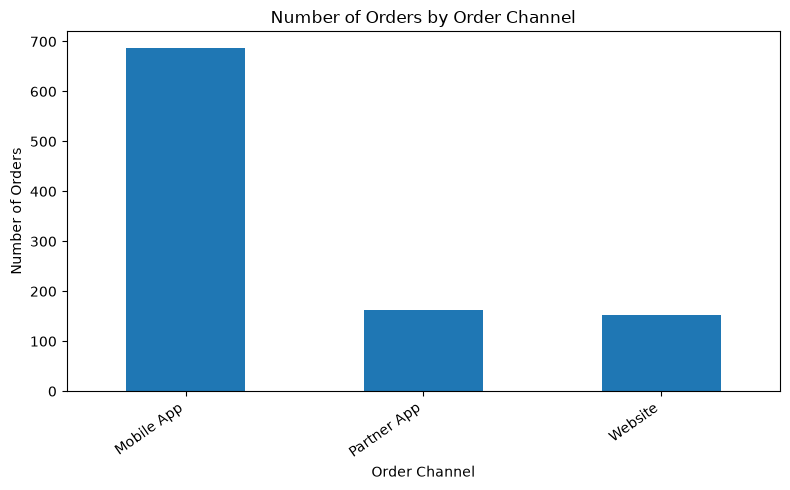

In [28]:
if "Order Channel" in work_df.columns:
    counts = work_df["Order Channel"].dropna().value_counts()
    plt.figure(figsize=(8, 5))
    counts.plot(kind="bar")
    plt.title("Number of Orders by Order Channel")
    plt.xlabel("Order Channel")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

**Interpretation:** The tallest bar is the channel with the most recorded orders. This describes channel popularity in the dataset; it does not explain why customers selected that channel.

### Chart 2 — Number of orders by Payment Method
This chart shows payment-method frequencies. The `Unknown` category is kept visible so missing payment information is not hidden.

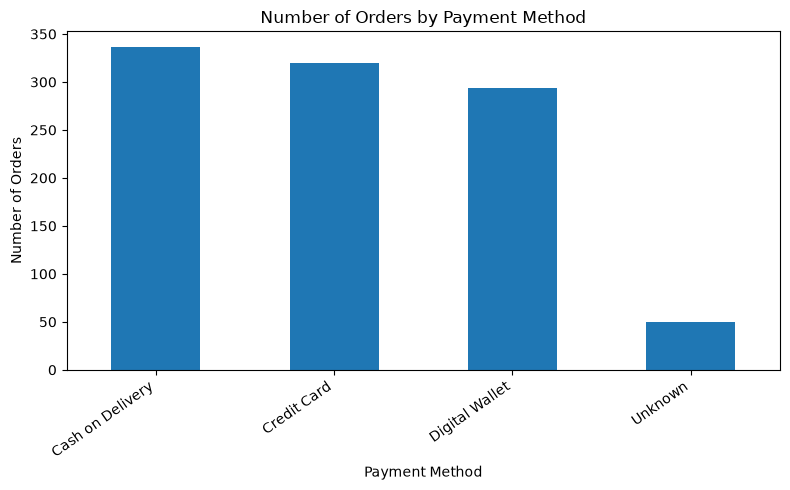

In [29]:
if "Payment Method" in work_df.columns:
    counts = work_df["Payment Method"].fillna("Unknown").value_counts()
    plt.figure(figsize=(8, 5))
    counts.plot(kind="bar")
    plt.title("Number of Orders by Payment Method")
    plt.xlabel("Payment Method")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

**Interpretation:** The chart shows which payment methods are most frequently recorded. A large `Unknown` bar would indicate that payment-method data completeness needs attention.

### Optional Chart 3 — Average delivery time by Weather Condition
This chart compares mean valid delivery durations by weather category. Differences are descriptive and may also be related to distance, traffic, restaurant preparation, or order volume.

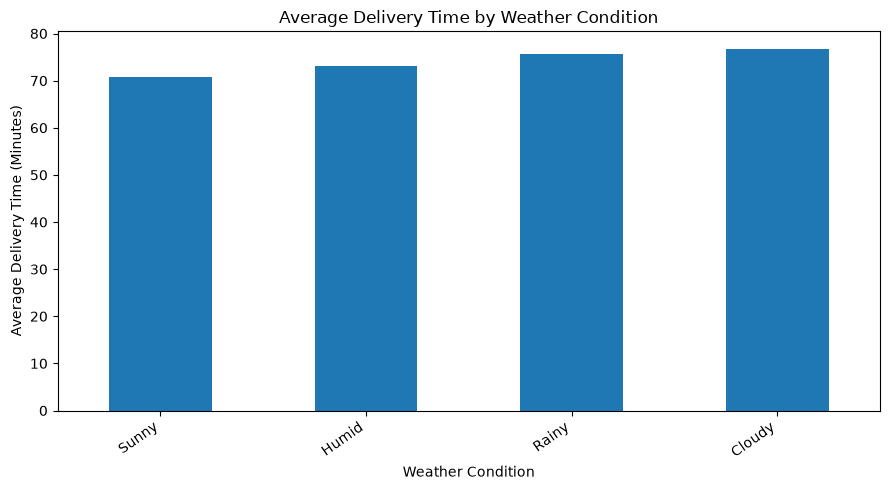

In [30]:
if "Weather Condition" in work_df.columns:
    weather_means = work_df.loc[
        work_df["Delivery_Time_Minutes"].notna()
        & (work_df["Delivery_Time_Minutes"] >= 0)
    ].groupby("Weather Condition")["Delivery_Time_Minutes"].mean().sort_values()
    if not weather_means.empty:
        plt.figure(figsize=(9, 5))
        weather_means.plot(kind="bar")
        plt.title("Average Delivery Time by Weather Condition")
        plt.xlabel("Weather Condition")
        plt.ylabel("Average Delivery Time (Minutes)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("No valid delivery durations available for this chart.")

**Interpretation:** The chart compares average delivery durations across weather categories. It can identify groups for further investigation but does not prove that weather caused a difference.

### Task 7 — Conclusion
The first two charts show order distribution by channel and payment method. The optional chart compares observed delivery times by weather. These visualizations support exploration but do not establish causation.

**Task 8 — Validate the Transformed Dataset**

This code checks whether all required original and derived columns are present in work_df. It helps identify any missing columns before performing the final analysis

In [31]:
expected_columns = [
    "Order ID", "Customer ID", "Restaurant ID",
    "Order Date and Time", "Delivery Date and Time",
    "Order Value", "Delivery Fee", "Payment Method",
    "Discounts and Offers", "Commission Fee",
    "Payment Processing Fee", "Refunds/Chargebacks",
    "Weather Condition", "Order Channel",
    "Delivery_Time_Minutes", "Order_Date",
    "Order_Hour", "Platform_Net_Revenue"
]

missing_columns = [
    col for col in expected_columns
    if col not in work_df.columns
]

print("Expected columns:", len(expected_columns))
print("Available columns:", len(expected_columns) - len(missing_columns))
print("Missing columns:", missing_columns if missing_columns else "None")

Expected columns: 18
Available columns: 18
Missing columns: None


In [32]:
type_expectations = {
    "Order Date and Time": "datetime",
    "Delivery Date and Time": "datetime",
    "Order Value": "numeric",
    "Delivery Fee": "numeric",
    "Commission Fee": "numeric",
    "Payment Processing Fee": "numeric",
    "Refunds/Chargebacks": "numeric",
    "Delivery_Time_Minutes": "numeric",
    "Platform_Net_Revenue": "numeric"
}

for col, expected_type in type_expectations.items():

    if col not in work_df.columns:
        print(f"{col}: Column missing")
        continue

    if expected_type == "datetime":
        result = pd.api.types.is_datetime64_any_dtype(work_df[col])

    else:
        result = pd.api.types.is_numeric_dtype(work_df[col])

    print(
        f"{col}: {work_df[col].dtype} | "
        f"Validation: {'Passed' if result else 'Failed'}"
    )

Order Date and Time: datetime64[us] | Validation: Passed
Delivery Date and Time: datetime64[us] | Validation: Passed
Order Value: float64 | Validation: Passed
Delivery Fee: float64 | Validation: Passed
Commission Fee: float64 | Validation: Passed
Payment Processing Fee: float64 | Validation: Passed
Refunds/Chargebacks: float64 | Validation: Passed
Delivery_Time_Minutes: float64 | Validation: Passed
Platform_Net_Revenue: float64 | Validation: Passed


In [33]:
print("Fully duplicated rows remaining:",
      work_df.duplicated().sum())

repeated_ids = work_df[
    work_df["Order ID"].duplicated(keep=False)
]

print("Rows with repeated Order IDs:", len(repeated_ids))

print("Distinct repeated Order IDs:",
      repeated_ids["Order ID"].nunique())

display(repeated_ids.head(20))

Fully duplicated rows remaining: 0
Rows with repeated Order IDs: 0
Distinct repeated Order IDs: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue,Delivery_Time_Flag


In [34]:
valid_duration_mask = (
    work_df["Delivery_Time_Minutes"].notna()
    & (work_df["Delivery_Time_Minutes"] >= 0)
    & (work_df["Delivery_Time_Flag"] == "Valid")
)

negative_duration = work_df[
    work_df["Delivery_Time_Minutes"] < 0
]

flagged_records = work_df[
    work_df["Delivery_Time_Flag"] != "Valid"
]

print("Valid delivery duration records:",
      valid_duration_mask.sum())

print("Negative delivery durations:",
      len(negative_duration))

print("Flagged delivery records:",
      len(flagged_records))

display(
    flagged_records[
        [
            "Order ID",
            "Delivery_Time_Minutes",
            "Delivery_Time_Flag"
        ]
    ].head(20)
)

Valid delivery duration records: 1000
Negative delivery durations: 0
Flagged delivery records: 0


,Order ID,Delivery_Time_Minutes,Delivery_Time_Flag


In [35]:
manual_check = work_df[
    work_df["Order Date and Time"].notna()
    & work_df["Delivery Date and Time"].notna()
][
    [
        "Order ID",
        "Order Date and Time",
        "Delivery Date and Time",
        "Delivery_Time_Minutes"
    ]
].head(5).copy()

manual_check["Manual_Duration_Minutes"] = (
    manual_check["Delivery Date and Time"]
    - manual_check["Order Date and Time"]
).dt.total_seconds() / 60

manual_check["Calculation Correct"] = np.isclose(
    manual_check["Delivery_Time_Minutes"],
    manual_check["Manual_Duration_Minutes"],
    equal_nan=True
)

display(manual_check)

,Order ID,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Manual_Duration_Minutes,Calculation Correct
0,1,2024-02-01 01:11:52,2024-02-01 02:39:52,88.0,88.0,True
1,2,2024-02-02 22:11:04,2024-02-02 22:46:04,35.0,35.0,True
2,3,2024-01-31 05:54:35,2024-01-31 06:52:35,58.0,58.0,True
3,4,2024-01-16 22:52:49,2024-01-16 23:38:49,46.0,46.0,True
4,5,2024-01-29 01:19:30,2024-01-29 02:48:30,89.0,89.0,True


In [36]:
revenue_check = work_df[
    work_df[revenue_components].notna().all(axis=1)
][
    revenue_components + ["Platform_Net_Revenue"]
].head(5).copy()

revenue_check["Manual_Revenue_Check"] = (
    revenue_check["Commission Fee"]
    + revenue_check["Delivery Fee"]
    - revenue_check["Payment Processing Fee"]
    - revenue_check["Refunds/Chargebacks"]
)

revenue_check["Calculation Correct"] = np.isclose(
    revenue_check["Platform_Net_Revenue"],
    revenue_check["Manual_Revenue_Check"],
    equal_nan=True
)

display(revenue_check)

,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue,Manual_Revenue_Check,Calculation Correct
0,150.0,0.0,47.0,0.0,103.0,103.0,True
1,198.0,40.0,23.0,0.0,215.0,215.0,True
2,195.0,30.0,45.0,0.0,180.0,180.0,True
5,92.0,20.0,27.0,150.0,-65.0,-65.0,True
6,144.0,30.0,12.0,50.0,112.0,112.0,True


In [37]:
missing_comparison = pd.DataFrame({
    "Before Cleaning": raw_df.isnull().sum(),
    "After Cleaning": work_df.isnull().sum()
})

missing_comparison["Before Cleaning (%)"] = (
    raw_df.isnull().mean() * 100
).round(2)

missing_comparison["After Cleaning (%)"] = (
    work_df.isnull().mean() * 100
).round(2)

display(missing_comparison)

,Before Cleaning,After Cleaning,Before Cleaning (%),After Cleaning (%)
Commission Fee,40.0,40,3.96,4.0
Customer ID,0.0,0,0.00,0.0
Delivery Date and Time,0.0,0,0.00,0.0
Delivery Fee,50.0,50,4.95,5.0
Delivery_Time_Flag,NaN,0,NaN,0.0
Delivery_Time_Minutes,NaN,0,NaN,0.0
Discounts and Offers,242.0,0,23.96,0.0
Order Channel,0.0,0,0.00,0.0
Order Date and Time,0.0,0,0.00,0.0
Order ID,0.0,0,0.00,0.0


In [38]:
original_records = len(raw_df)
cleaned_records = len(work_df)

records_removed = original_records - cleaned_records

order_value_excluded = work_df["Order Value"].isna().sum()

delivery_excluded = (~valid_duration_mask).sum()

revenue_excluded = (
    work_df["Platform_Net_Revenue"].isna().sum()
)

validation_summary = pd.DataFrame({
    "Description": [
        "Original records",
        "Records retained after cleaning",
        "Records removed",
        "Records excluded from Order Value calculations",
        "Records excluded from delivery-time calculations",
        "Records excluded from Platform Net Revenue calculations"
    ],

    "Count": [
        original_records,
        cleaned_records,
        records_removed,
        order_value_excluded,
        delivery_excluded,
        revenue_excluded
    ]
})

display(validation_summary)

,Description,Count
0,Original records,1010
1,Records retained after cleaning,1000
2,Records removed,10
3,Records excluded from Order Value calculations,40
4,Records excluded from delivery-time calculations,0
5,Records excluded from Platform Net Revenue cal...,172


**Task 8 — Conclusion**

Markdown cell:

The validation process checks whether the cleaned dataset contains all expected columns and appropriate data types. Fully duplicated rows are checked to ensure they have been handled according to the cleaning rules, while repeated Order IDs are investigated separately.

Delivery durations are validated to ensure that records classified as valid do not contain negative values. Manual checks confirm that delivery-time and Platform Net Revenue calculations follow the required formulas.

Missing values are compared before and after cleaning to understand the impact of data-cleaning operations. The final validation summary reports the number of records removed, retained, and excluded from important calculations.

Overall, successful validation does not mean that every missing value must be zero. It means that remaining data-quality issues are understood, documented, and handled consistently.